# Previous-year ENSO and IOD (post-hoc)

Correlates the previous-winter ONI / Niño 3.4 and the previous-autumn DMI with detrended and raw MHW days and events of the following year, with leave-one-year-out checks and a partial correlation for the IOD.

**Thesis:** Sections 3.15, 4.12 · Tables 4.16, A.5 · Fig. 4.15 · Appendix C.13  
**Input:** predictor_table_1982_2025.csv, NOAA CPC ONI  
**Output:** wp7_enso_iod_*.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

# Previous-year ENSO and IOD vs MHWs in the study box (WP7)

**Question.** Does a high ONI / Niño 3.4 in Nov–Jan, or a positive IOD in Sep–Nov, of the previous
year go with more MHW days and events in the following year over 15–23°N, 85–93°E?

**Predictors (one value per year).** For response year Y:
ONI NDJ (Nov Y−1 to Jan Y, NOAA CPC); Niño 3.4 NDJ (ERSST v5, 1991–2020 base, same months);
DMI SON (Sep–Nov Y−1, daily DMI of Section 3.1.3). ONI and Niño 3.4 NDJ are almost the same series.

**Responses.** Detrended labels (main) and raw labels (secondary): MHW days and number of events
(by onset date) in Feb–Dec of Y. January is left out because it is inside the NDJ window.
Mar–Jun (Gao et al., 2022, season) is also reported. Years Y = 1983–2025 (n = 43).

**Decision rules (fixed before running).**
ENSO: supported if Spearman r between ONI NDJ(Y−1) and detrended Feb–Dec MHW days is positive with
p < 0.05 and stays positive when any single year is left out.
IOD: has an effect of its own if the partial Spearman r of DMI SON(Y−1) with detrended Feb–Dec MHW
days, controlling for Niño 3.4 NDJ(Y−1), has p < 0.05.

In [1]:
# [E1] data
from google.colab import drive; drive.mount('/content/drive')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

PROC = '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed'
FIG = f'{PROC}/figures'; os.makedirs(FIG, exist_ok=True)
YRS = np.arange(1983, 2026)

df = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
assert {'dmi', 'mhw_detrended', 'mhw_raw'} <= set(df.columns), list(df.columns)

# monthly Nino 3.4 anomaly (not the one-month-shifted daily copy in the predictor table)
n = pd.read_csv('https://www.cpc.ncep.noaa.gov/data/indices/ersst5.nino.mth.91-20.ascii', sep=r'\s+')
n34 = pd.Series(n.iloc[:, -1].values, index=pd.to_datetime(dict(year=n.YR, month=n.MON, day=1)))

def ndj(y):
    v = n34.reindex([pd.Timestamp(y - 1, 11, 1), pd.Timestamp(y - 1, 12, 1), pd.Timestamp(y, 1, 1)]).values
    assert np.isfinite(v).all(), f'Nino 3.4 missing for NDJ before {y}'
    return v.mean()

X = pd.DataFrame(index=YRS)
X['nino34_NDJ'] = [ndj(y) for y in YRS]

# ONI: find which year label the NDJ row uses by matching it to the Nino 3.4 NDJ just computed
o = pd.read_csv('https://www.cpc.ncep.noaa.gov/data/indices/oni.ascii.txt', sep=r'\s+')
o_ndj = o[o.SEAS == 'NDJ'].set_index('YR').ANOM
cand = {'Nov year': pd.Series(o_ndj.reindex(YRS - 1).values, index=YRS),
        'Jan year': pd.Series(o_ndj.reindex(YRS).values, index=YRS)}
rc = {k: v.corr(X.nino34_NDJ) for k, v in cand.items()}
key = max(rc, key=rc.get)
print('ONI NDJ year label =', key, '| r with Nino 3.4 NDJ:', {k: round(v, 3) for k, v in rc.items()})
assert rc[key] > 0.95
X['oni_NDJ'] = cand[key]
assert X.oni_NDJ.notna().all(), X[X.oni_NDJ.isna()]

son = df.dmi[df.index.month.isin([9, 10, 11])]
X['dmi_SON'] = son.groupby(son.index.year).mean().reindex(YRS - 1).values
assert X.notna().all().all()
print(f'r(ONI NDJ, Nino 3.4 NDJ) = {X.oni_NDJ.corr(X.nino34_NDJ):.3f} | '
      f'Spearman r(Nino 3.4 NDJ, DMI SON) = {stats.spearmanr(X.nino34_NDJ, X.dmi_SON)[0]:.2f}')

def responses(lab):
    lab = lab.astype(int)
    onset = (lab == 1) & (lab.shift(1, fill_value=0) == 0)
    R = pd.DataFrame(index=YRS)
    for name, months in (('FebDec', range(2, 13)), ('MAMJ', range(3, 7))):
        m = lab.index.month.isin(list(months))
        R[f'days_{name}'] = lab[m].groupby(lab.index[m].year).sum().reindex(YRS, fill_value=0).values
        R[f'events_{name}'] = onset[m].groupby(lab.index[m].year).sum().reindex(YRS, fill_value=0).values
    return R

RESP = {'detrended': responses(df.mhw_detrended), 'raw': responses(df.mhw_raw)}

Mounted at /content/drive
ONI NDJ year label = Nov year | r with Nino 3.4 NDJ: {'Nov year': np.float64(0.997), 'Jan year': np.float64(-0.118)}
r(ONI NDJ, Nino 3.4 NDJ) = 0.997 | Spearman r(Nino 3.4 NDJ, DMI SON) = 0.57


In [2]:
# [E2] correlations
def partial(x, y, z, rank=True):
    if rank: x, y, z = (stats.rankdata(v) for v in (x, y, z))
    ex = x - np.polyval(np.polyfit(z, x, 1), z)
    ey = y - np.polyval(np.polyfit(z, y, 1), z)
    r = np.corrcoef(ex, ey)[0, 1]; k = len(x) - 3
    return r, 2 * stats.t.sf(abs(r * np.sqrt(k / (1 - r ** 2))), k)

def spear(x, y): return tuple(stats.spearmanr(x, y))
def pears(x, y): return tuple(stats.pearsonr(x, y))
def loyo(f, *a):
    rs = [f(*(np.delete(np.asarray(v, float), i) for v in a))[0] for i in range(len(a[0]))]
    return min(rs), max(rs)

z = X.nino34_NDJ.values
rows = []
for lt, R in RESP.items():
    for resp in R.columns:
        y = R[resp].values.astype(float)
        for pred, f, args, pf in (
                ('ONI NDJ', spear, (X.oni_NDJ.values,), lambda: pears(X.oni_NDJ.values, y)),
                ('Nino 3.4 NDJ', spear, (X.nino34_NDJ.values,), lambda: pears(X.nino34_NDJ.values, y)),
                ('DMI SON', spear, (X.dmi_SON.values,), lambda: pears(X.dmi_SON.values, y)),
                ('DMI SON | Nino 3.4', lambda a, b, c: partial(a, b, c), (X.dmi_SON.values,),
                 lambda: partial(X.dmi_SON.values, y, z, rank=False))):
            extra = (z,) if pred.startswith('DMI SON |') else ()
            r, p = f(*args, y, *extra)
            lo, hi = loyo(f, *args, y, *extra)
            rp, pp = pf()
            rows.append({'labels': lt, 'response': resp, 'predictor (year before)': pred,
                         'Spearman r': round(r, 2), 'p': round(p, 3),
                         'LOYO r range': f'{lo:+.2f} to {hi:+.2f}', 'Pearson r': round(rp, 2), 'Pearson p': round(pp, 3)})
T = pd.DataFrame(rows)
T.to_csv(f'{PROC}/wp7_enso_iod_lag.csv', index=False)
pd.set_option('display.width', 250)
print(T.to_string(index=False))

D = RESP['detrended']
r, p = stats.spearmanr(X.oni_NDJ, D.days_FebDec); lo, _ = loyo(spear, X.oni_NDJ.values, D.days_FebDec.values)
print(f'\nENSO RULE: Spearman r = {r:.2f}, p = {p:.3f}, lowest LOYO r = {lo:+.2f} ->',
      'SUPPORTED' if (r > 0 and p < 0.05 and lo > 0) else 'NOT SUPPORTED')
r, p = partial(X.dmi_SON.values, D.days_FebDec.values.astype(float), z)
print(f'IOD RULE: partial Spearman r = {r:.2f}, p = {p:.3f} ->', 'OWN EFFECT' if p < 0.05 else 'NO OWN EFFECT')

   labels      response predictor (year before)  Spearman r     p   LOYO r range  Pearson r  Pearson p
detrended   days_FebDec                 ONI NDJ        0.40 0.008 +0.36 to +0.46       0.51      0.000
detrended   days_FebDec            Nino 3.4 NDJ        0.39 0.009 +0.35 to +0.46       0.50      0.001
detrended   days_FebDec                 DMI SON        0.26 0.095 +0.20 to +0.30       0.40      0.007
detrended   days_FebDec      DMI SON | Nino 3.4        0.05 0.776 -0.02 to +0.10       0.13      0.412
detrended events_FebDec                 ONI NDJ        0.40 0.008 +0.36 to +0.46       0.52      0.000
detrended events_FebDec            Nino 3.4 NDJ        0.39 0.011 +0.34 to +0.45       0.51      0.000
detrended events_FebDec                 DMI SON        0.18 0.252 +0.12 to +0.22       0.28      0.067
detrended events_FebDec      DMI SON | Nino 3.4       -0.06 0.728 -0.13 to -0.01      -0.07      0.675
detrended     days_MAMJ                 ONI NDJ        0.47 0.001 +0.43 t

In [3]:
# [E3] El Nino / neutral / La Nina composites (detrended labels)
ph = pd.cut(X.oni_NDJ, [-np.inf, -0.5, 0.5, np.inf], right=False, labels=['La Nina', 'Neutral', 'El Nino'])
C = D.assign(phase=ph.values).groupby('phase', observed=True)[['days_FebDec', 'events_FebDec']].agg(['mean', 'median', 'count'])
print(C.round(1).to_string())
el = ph == 'El Nino'
u = stats.mannwhitneyu(D.days_FebDec[el], D.days_FebDec[~el], alternative='greater')
print(f'MHW days Feb-Dec, years after El Nino vs all others: Mann-Whitney one-sided p = {u.pvalue:.3f}')
print('\nYears after El Nino (ONI NDJ >= 0.5):')
print(X.loc[el, ['oni_NDJ']].join(D.loc[el, ['days_FebDec', 'events_FebDec', 'days_MAMJ']]).round(2).to_string())

        days_FebDec              events_FebDec             
               mean median count          mean median count
phase                                                      
La Nina        14.7    7.5    16           1.5    1.0    16
Neutral        19.2   16.0    12           2.1    1.5    12
El Nino        40.6   35.0    15           3.6    3.0    15
MHW days Feb-Dec, years after El Nino vs all others: Mann-Whitney one-sided p = 0.014

Years after El Nino (ONI NDJ >= 0.5):
      oni_NDJ  days_FebDec  events_FebDec  days_MAMJ
1983     2.12           46              5         29
1987     1.21           97              6         16
1988     1.00           66              6         25
1992     1.43            0              0          0
1995     0.97           17              1         17
1998     2.37          107             10         33
2003     1.08            7              1          7
2005     0.71           12              2          6
2007     0.88           12            

 month  r ONI  p ONI  partial r DMI  p DMI  mean MHW days
     2  0.246  0.112         -0.214  0.173          1.372
     3  0.337  0.027         -0.190  0.229          1.791
     4  0.251  0.104          0.005  0.974          2.605
     5  0.371  0.014          0.008  0.960          3.465
     6  0.292  0.057          0.207  0.187          2.349
     7  0.263  0.089          0.065  0.684          2.581
     8  0.125  0.423          0.020  0.900          2.860
     9  0.087  0.581          0.099  0.533          2.395
    10  0.210  0.177         -0.152  0.337          2.279
    11  0.327  0.033         -0.048  0.763          1.512
    12  0.092  0.560          0.234  0.135          1.767


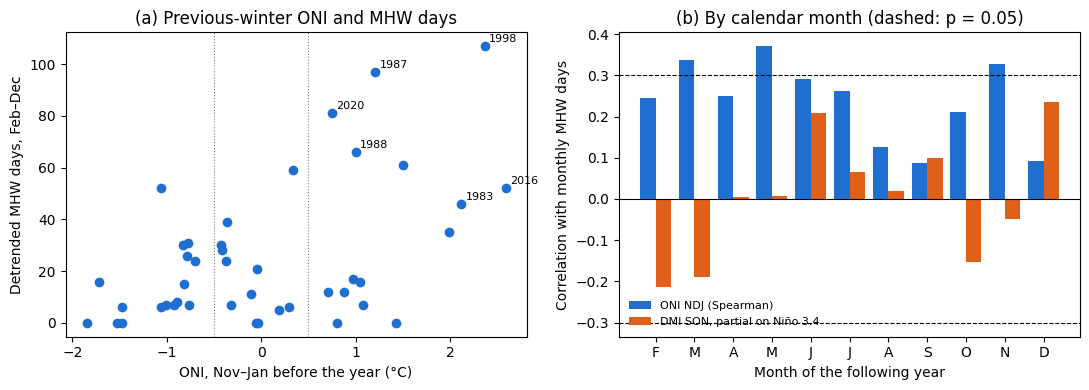

In [4]:
# [E4] by calendar month of year Y (as Gao et al., 2022, Fig. 6)
lab = df.mhw_detrended.astype(int)
M = []
for m in range(2, 13):
    s = lab[lab.index.month == m]
    y = s.groupby(s.index.year).sum().reindex(YRS, fill_value=0).values.astype(float)
    r1, p1 = stats.spearmanr(X.oni_NDJ, y)
    r2, p2 = partial(X.dmi_SON.values, y, z)
    M.append({'month': m, 'r ONI': r1, 'p ONI': p1, 'partial r DMI': r2, 'p DMI': p2, 'mean MHW days': y.mean()})
M = pd.DataFrame(M); M.to_csv(f'{PROC}/wp7_enso_iod_monthly.csv', index=False)
print(M.round(3).to_string(index=False))

r_crit = (lambda t: t / np.sqrt(43 - 2 + t ** 2))(stats.t.ppf(0.975, 41))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(X.oni_NDJ, D.days_FebDec, color='#1f6fd1')
for yr in D.days_FebDec.nlargest(4).index.union(X.oni_NDJ.nlargest(3).index):
    ax[0].annotate(str(yr), (X.oni_NDJ[yr], D.days_FebDec[yr]), fontsize=8, xytext=(3, 3), textcoords='offset points')
ax[0].axvline(0.5, color='grey', ls=':', lw=0.8); ax[0].axvline(-0.5, color='grey', ls=':', lw=0.8)
ax[0].set_xlabel('ONI, Nov–Jan before the year (°C)'); ax[0].set_ylabel('Detrended MHW days, Feb–Dec')
ax[0].set_title('(a) Previous-winter ONI and MHW days')
xm = np.arange(2, 13)
ax[1].bar(xm - 0.2, M['r ONI'], 0.4, color='#1f6fd1', label='ONI NDJ (Spearman)')
ax[1].bar(xm + 0.2, M['partial r DMI'], 0.4, color='#e0601a', label='DMI SON, partial on Niño 3.4')
for s_ in (1, -1): ax[1].axhline(s_ * r_crit, color='k', ls='--', lw=0.8)
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_xticks(xm); ax[1].set_xticklabels(list('FMAMJJASOND'))
ax[1].set_xlabel('Month of the following year'); ax[1].set_ylabel('Correlation with monthly MHW days')
ax[1].set_title('(b) By calendar month (dashed: p = 0.05)'); ax[1].legend(fontsize=8, frameon=False, loc='lower left')
plt.tight_layout(); plt.savefig(f'{FIG}/fig_wp7_enso_iod_lag.png', dpi=300); plt.show()